# BÀI THỰC HÀNH CHƯƠNG 2 (PHẦN 2) — CANNY EDGE DETECTOR

**Thư viện:** OpenCV, scikit-image, NumPy và Matplotlib.
**Nội dung:** phần **II> Bài tập thực hành** (slide 26):
1. Thực hiện Canny bằng `cv2.Canny` (OpenCV) và `skimage.feature.canny` (scikit-image).
2. Thay đổi sigma, ngưỡng thấp, ngưỡng cao và so sánh với giá trị mặc định.
3. Áp dụng Canny cho ảnh nhiều nhiễu, ảnh tương phản thấp, ảnh nhiều chi tiết; đánh giá và kết luận.
4. Kết hợp Canny với phân đoạn (tìm vùng) và nhận dạng hình dạng (tìm đối tượng).

### Cách sử dụng
1. Chọn kernel Python của `.venv` rồi chạy **Run All** từ trên xuống.
2. Ảnh đầu vào lấy từ `skimage.data` (có sẵn trong thư viện, không cần Internet). Muốn dùng ảnh riêng thì bỏ ảnh vào `du_lieu/` và sửa dòng đọc ảnh ở mục 2, ví dụ `cv2.imread("du_lieu/ten_anh.jpg", cv2.IMREAD_GRAYSCALE)`.
3. Mỗi ảnh kết quả được lưu thành **một file riêng** trong `ket_qua/<tên bài>/`, ví dụ `ket_qua/bai1_opencv_vs_skimage/02_cv2_canny_100_200.png`.

### Nhắc lại 5 bước của Canny
1. **Giảm nhiễu:** làm mờ ảnh bằng bộ lọc Gaussian (tham số **sigma**).
2. **Tính gradient:** dùng Sobel để tính độ lớn và hướng gradient.
3. **Non-maximum suppression:** chỉ giữ điểm có gradient lớn nhất theo hướng gradient, cho cạnh mảnh 1 pixel.
4. **Ngưỡng kép:** gradient > ngưỡng cao → cạnh mạnh; nằm giữa hai ngưỡng → cạnh yếu; < ngưỡng thấp → bỏ.
5. **Theo dõi cạnh (hysteresis):** cạnh yếu chỉ được giữ nếu nối với cạnh mạnh.

## 1. Khai báo thư viện
- `cv2.Canny` thực hiện bước 2–5. **Không có bước Gaussian** bên trong, nên muốn chỉnh sigma phải tự làm mờ trước bằng `cv2.GaussianBlur`.
- `skimage.feature.canny` thực hiện đủ 5 bước, có sẵn tham số `sigma`.
- `show_images` là hàm phụ: trong notebook hiển thị các ảnh cạnh nhau để dễ so sánh, còn khi lưu thì **mỗi ảnh là một file riêng** (đúng kích thước gốc, không có tiêu đề) trong `ket_qua/<tên bài>/`, đánh số theo thứ tự hiển thị. `file_name` đổi tiêu đề tiếng Việt thành tên file không dấu.

In [1]:
from pathlib import Path
import re
import unicodedata
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
from skimage import data, feature

OUTPUT_DIR = Path("ket_qua")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
Path("du_lieu").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
print("OpenCV:", cv2.__version__, "| scikit-image:", skimage.__version__)

def file_name(title):
    """Đổi tiêu đề ảnh thành tên file không dấu, vd 'cv2.Canny(100, 200)' → 'cv2_canny_100_200'."""
    text = unicodedata.normalize("NFKD", title.split("\n")[0].replace("đ", "d").replace("Đ", "D"))
    text = text.encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", "_", text).strip("_")

def show_images(images, titles, cols=4, save_dir=None):
    """Hiển thị ảnh thành lưới để so sánh; nếu có save_dir thì lưu TỪNG ẢNH thành file riêng."""
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
    fig.tight_layout()
    plt.show()
    if save_dir:
        folder = OUTPUT_DIR / save_dir
        folder.mkdir(parents=True, exist_ok=True)
        for i, (image, title) in enumerate(zip(images, titles), start=1):
            out = image.astype(np.uint8) * 255 if image.dtype == bool else image
            if out.ndim == 3:
                out = cv2.cvtColor(out, cv2.COLOR_RGB2BGR)
            cv2.imwrite(str(folder / f"{i:02d}_{file_name(title)}.png"), out)

OpenCV: 5.0.0 | scikit-image: 0.26.0


### Hàm phụ: tỉ lệ pixel cạnh (ngoài slide)
**Dùng để làm gì:** đếm phần trăm pixel được đánh dấu là cạnh. Đây là con số đơn giản để **so sánh định lượng** giữa các lần chạy, bên cạnh việc nhìn ảnh bằng mắt:
- tỉ lệ quá cao → nhiều cạnh giả (thường do nhiễu hoặc ngưỡng quá thấp);
- tỉ lệ quá thấp → mất cạnh (ngưỡng quá cao hoặc làm mờ quá mạnh).

In [2]:
def edge_ratio(edges):
    """Phần trăm pixel cạnh trong ảnh cạnh (uint8 0/255 hoặc bool)."""
    return 100 * np.count_nonzero(edges) / edges.size

## 2. Ảnh đầu vào
Ảnh chính là `camera` (512×512, ảnh xám): có người, chân máy, toà nhà nền xa nên có cả cạnh rõ lẫn chi tiết nhỏ. Canny làm việc trên **ảnh xám**; với ảnh màu phải chuyển sang xám trước (`cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)`).

Kích thước: (512, 512) | kiểu: uint8 | min/max: 0 255


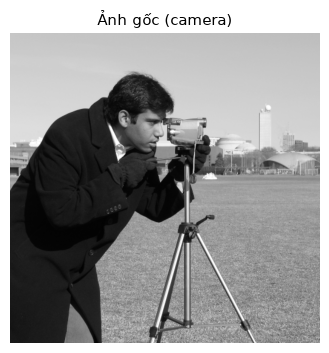

In [3]:
img = data.camera()          # hoặc: cv2.imread("du_lieu/ten_anh.jpg", cv2.IMREAD_GRAYSCALE)
print("Kích thước:", img.shape, "| kiểu:", img.dtype, "| min/max:", img.min(), img.max())
show_images([img], ["Ảnh gốc (camera)"], cols=1)

## Bài 1. Thực hiện Canny bằng OpenCV và scikit-image
- `cv2.Canny(img, 100, 200)`: ngưỡng thấp 100, ngưỡng cao 200. OpenCV **bắt buộc** truyền hai ngưỡng (không có giá trị mặc định); cặp 100/200 là cặp dùng trong tài liệu hướng dẫn của OpenCV. Kết quả là ảnh `uint8` với cạnh = 255.
- `feature.canny(img)`: dùng giá trị mặc định `sigma=1`, ngưỡng thấp = 10%, ngưỡng cao = 20% giá trị lớn nhất của kiểu dữ liệu. Kết quả là mảng `bool`.

OpenCV      : 7.51% pixel cạnh
scikit-image: 9.89% pixel cạnh


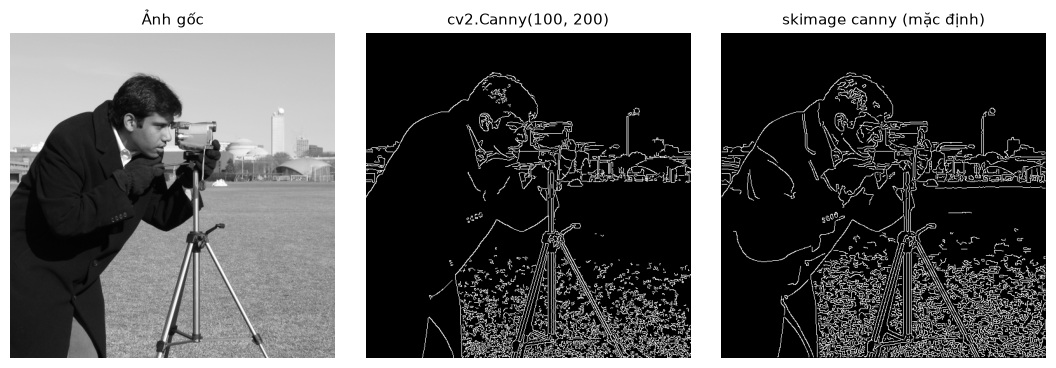

In [4]:
edges_cv = cv2.Canny(img, 100, 200)
edges_sk = feature.canny(img)

print(f"OpenCV      : {edge_ratio(edges_cv):.2f}% pixel cạnh")
print(f"scikit-image: {edge_ratio(edges_sk):.2f}% pixel cạnh")
show_images([img, edges_cv, edges_sk],
            ["Ảnh gốc", "cv2.Canny(100, 200)", "skimage canny (mặc định)"],
            cols=3, save_dir="bai1_opencv_vs_skimage")

**Nhận xét:**
- Cả hai đều bắt được các cạnh chính: người, chân máy, máy quay, toà nhà nền xa.
- scikit-image (mặc định) cho **nhiều cạnh hơn** (9.89% so với 7.51%), chủ yếu là cạnh vụn trên cỏ: ngưỡng mặc định 10%/20% khá thấp so với độ lớn gradient của vùng cỏ. Bù lại, nhờ làm mờ Gaussian `sigma=1` mà đường viền áo khoác và vai liền mạch hơn.
- OpenCV với 100/200 không làm mờ trước, nhưng ngưỡng cao hơn nên bỏ bớt cạnh trên cỏ; một số đoạn viền áo bị đứt.
- Con số ngưỡng của hai thư viện **không cùng thang đo**: OpenCV so ngưỡng với độ lớn Sobel tính trực tiếp trên giá trị pixel 0–255, còn scikit-image tính gradient trên ảnh đã chuẩn hoá về 0–1. Vì vậy chỉ so sánh **kết quả**, không so sánh trực tiếp con số ngưỡng giữa hai thư viện.

## Bài 2. Thay đổi tham số và quan sát kết quả
### 2.1. Thay đổi sigma (bước 1 — giảm nhiễu)
- scikit-image: truyền thẳng `sigma`, giữ ngưỡng mặc định.
- OpenCV: `cv2.Canny` không có sigma, nên làm đúng bước 1 của Canny bằng `cv2.GaussianBlur(img, (0, 0), sigma)` rồi mới gọi `cv2.Canny(…, 100, 200)`. `ksize=(0, 0)` để OpenCV tự tính kích thước kernel từ sigma.

sigma=0.5  skimage: 15.78%   OpenCV:  5.15%
sigma=1    skimage:  9.89%   OpenCV:  2.59%
sigma=2    skimage:  2.80%   OpenCV:  1.49%
sigma=3    skimage:  1.98%   OpenCV:  0.53%
sigma=5    skimage:  1.08%   OpenCV:  0.00%


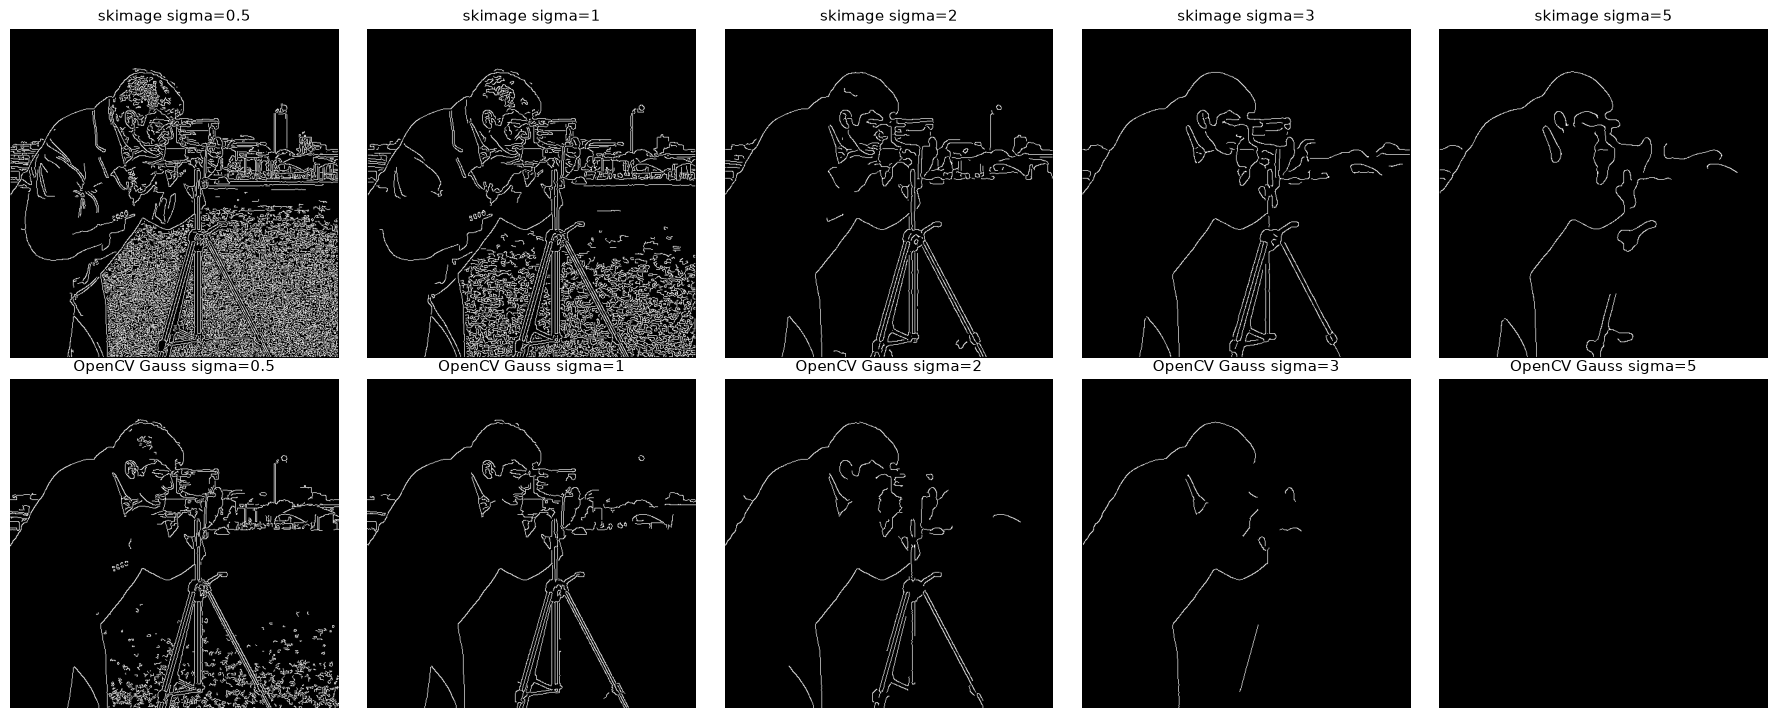

In [9]:
sigmas = [0.5, 1, 2, 3, 5]
sk_results = [feature.canny(img, sigma=s) for s in sigmas]
cv_results = [cv2.Canny(cv2.GaussianBlur(img, (0, 0), s), 100, 200) for s in sigmas]

for s, e_sk, e_cv in zip(sigmas, sk_results, cv_results):
    print(f"sigma={s:<4} skimage: {edge_ratio(e_sk):5.2f}%   OpenCV: {edge_ratio(e_cv):5.2f}%")
show_images(sk_results + cv_results,
            [f"skimage sigma={s}" for s in sigmas] + [f"OpenCV Gauss sigma={s}" for s in sigmas],
            cols=5, save_dir="bai2_sigma")

### 2.2. Thay đổi ngưỡng thấp (giữ ngưỡng cao)
Ngưỡng thấp quyết định **cạnh yếu** nào được giữ lại ở bước theo dõi cạnh (chỉ giữ khi nối với cạnh mạnh).
- OpenCV: ngưỡng cao cố định 200, ngưỡng thấp thay đổi.
- scikit-image (`sigma=1`): ngưỡng cao cố định 51 (= 20% của 255, mặc định), ngưỡng thấp thay đổi. Với ảnh `uint8`, ngưỡng truyền vào tính theo thang 0–255.

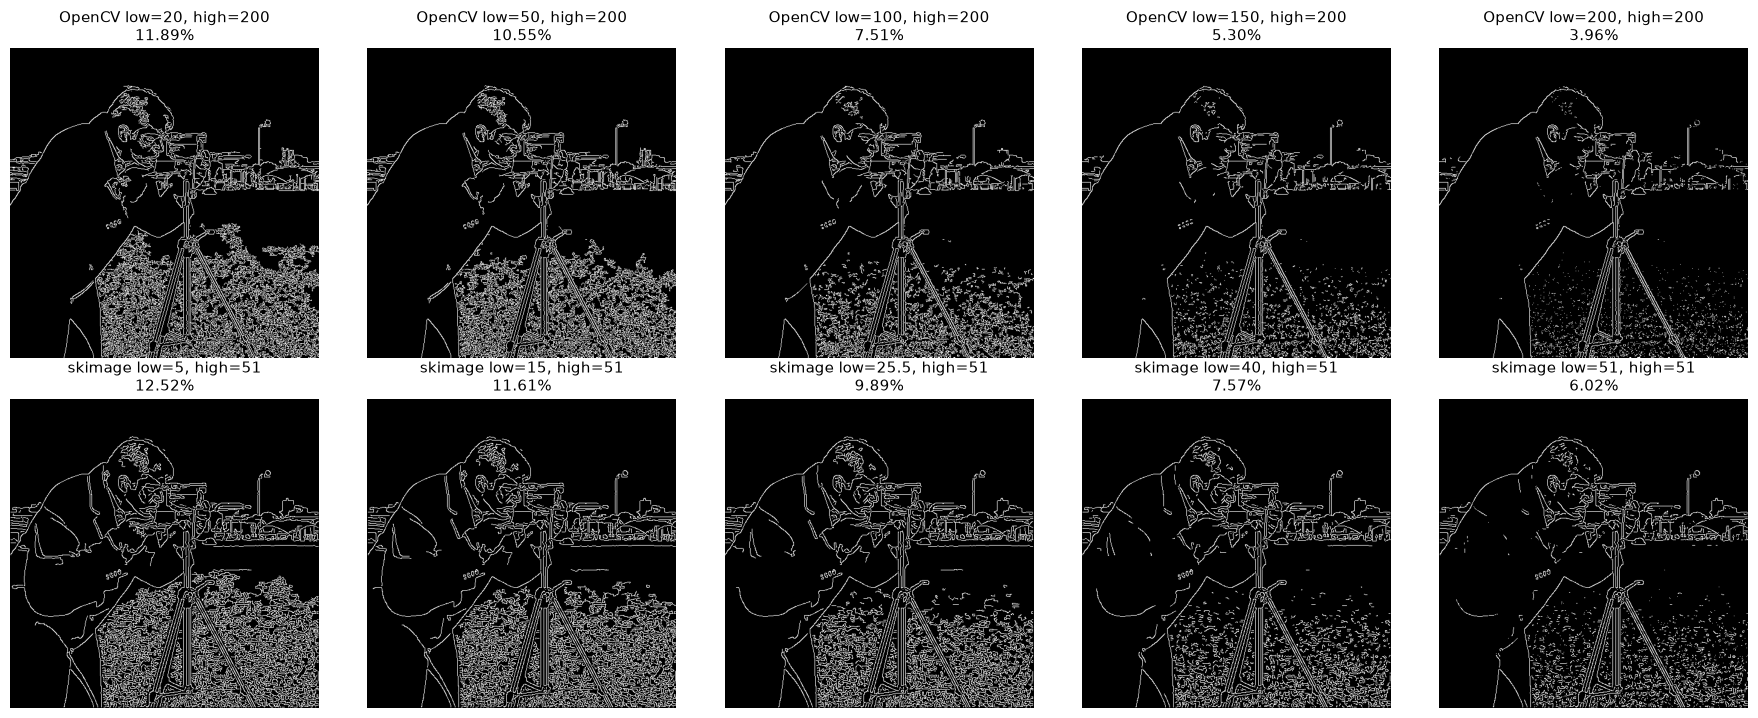

In [6]:
cv_lows = [20, 50, 100, 150, 200]
sk_lows = [5, 15, 25.5, 40, 51]
cv_results = [cv2.Canny(img, low, 200) for low in cv_lows]
sk_results = [feature.canny(img, low_threshold=low, high_threshold=51) for low in sk_lows]

show_images(cv_results + sk_results,
            [f"OpenCV low={l}, high=200\n{edge_ratio(e):.2f}%" for l, e in zip(cv_lows, cv_results)]
            + [f"skimage low={l}, high=51\n{edge_ratio(e):.2f}%" for l, e in zip(sk_lows, sk_results)],
            cols=5, save_dir="bai2_nguong_thap")

### 2.3. Thay đổi ngưỡng cao (giữ ngưỡng thấp)
Ngưỡng cao quyết định điểm nào là **cạnh mạnh** — điểm xuất phát của các đường cạnh.

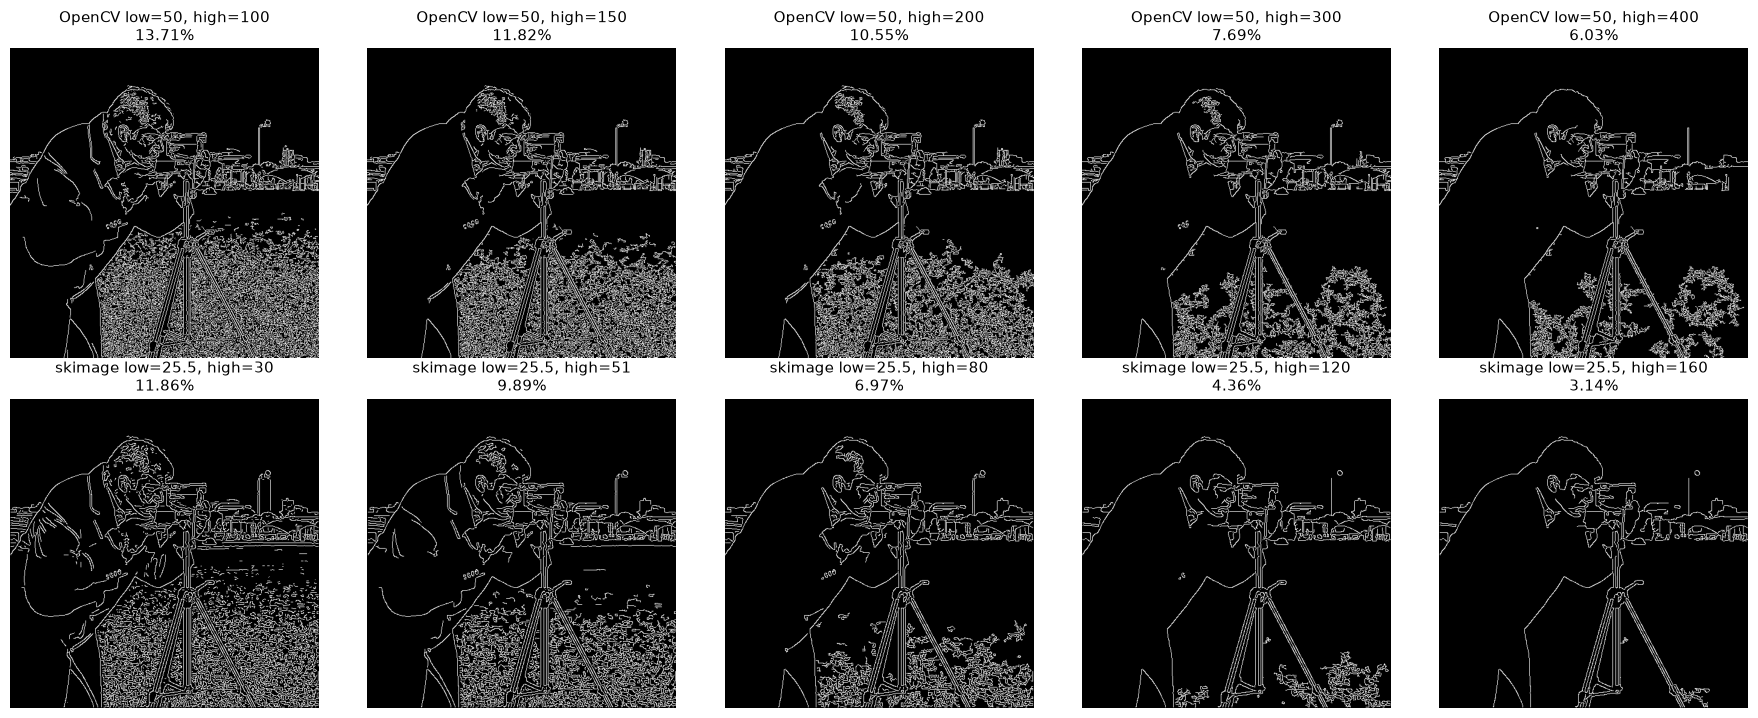

In [7]:
cv_highs = [100, 150, 200, 300, 400]
sk_highs = [30, 51, 80, 120, 160]
cv_results = [cv2.Canny(img, 50, high) for high in cv_highs]
sk_results = [feature.canny(img, low_threshold=25.5, high_threshold=high) for high in sk_highs]

show_images(cv_results + sk_results,
            [f"OpenCV low=50, high={h}\n{edge_ratio(e):.2f}%" for h, e in zip(cv_highs, cv_results)]
            + [f"skimage low=25.5, high={h}\n{edge_ratio(e):.2f}%" for h, e in zip(sk_highs, sk_results)],
            cols=5, save_dir="bai2_nguong_cao")

### 2.4. So sánh với giá trị mặc định
- scikit-image mặc định: `sigma=1`, ngưỡng 10% / 20%.
- OpenCV không có ngưỡng mặc định; dùng cặp 100/200 ở bài 1 làm mốc.

Bộ tham số chỉnh tay chọn theo quan sát ở 2.1–2.3: tăng sigma lên 2 để bỏ cạnh vụn ở vùng cỏ, giữ tỉ lệ ngưỡng cao : thấp khoảng 2 : 1 – 3 : 1 như khuyến nghị của Canny.

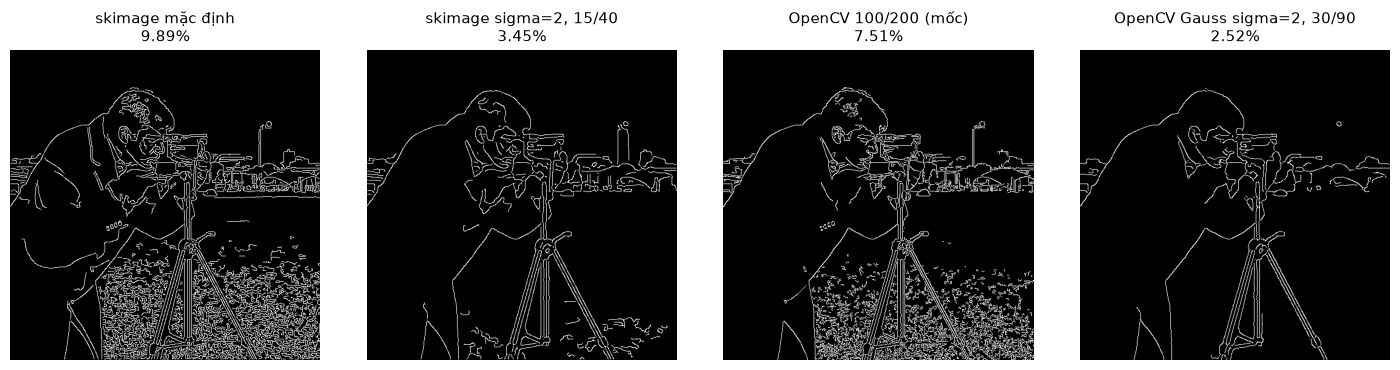

In [8]:
default_sk = feature.canny(img)
tuned_sk = feature.canny(img, sigma=2, low_threshold=15, high_threshold=40)
default_cv = cv2.Canny(img, 100, 200)
tuned_cv = cv2.Canny(cv2.GaussianBlur(img, (0, 0), 2), 30, 90)

show_images([default_sk, tuned_sk, default_cv, tuned_cv],
            [f"skimage mặc định\n{edge_ratio(default_sk):.2f}%",
             f"skimage sigma=2, 15/40\n{edge_ratio(tuned_sk):.2f}%",
             f"OpenCV 100/200 (mốc)\n{edge_ratio(default_cv):.2f}%",
             f"OpenCV Gauss sigma=2, 30/90\n{edge_ratio(tuned_cv):.2f}%"],
            cols=4, save_dir="bai2_so_sanh_mac_dinh")

### Nhận xét bài 2
**Sigma (2.1):** sigma càng lớn thì ảnh càng mờ, các biến thiên nhỏ (cỏ, nếp áo) bị xoá, chỉ còn cạnh của vật lớn. scikit-image: 15.78% (sigma 0.5) → 9.89% (sigma 1) → 2.80% (sigma 2) → 1.08% (sigma 5). Sigma quá lớn làm cạnh bị lệch vị trí và mất chi tiết: với OpenCV, sigma = 5 làm gradient nhỏ hơn ngưỡng 100/200 nên **không còn cạnh nào** (0.00%).

**Ngưỡng thấp (2.2):** ngưỡng thấp càng nhỏ thì càng nhiều cạnh yếu được nối vào cạnh mạnh → đường viền liền hơn nhưng vùng cỏ nhiều cạnh vụn (OpenCV 11.89% khi low = 20). Ngưỡng thấp tăng đến bằng ngưỡng cao thì bước hysteresis không còn tác dụng, cạnh bị đứt đoạn (OpenCV low = high = 200: 3.96%).

**Ngưỡng cao (2.3):** ngưỡng cao quyết định số điểm xuất phát (cạnh mạnh). Tăng ngưỡng cao → ít cạnh hơn, chỉ còn đường viền rõ (scikit-image 11.86% → 3.14%). Lưu ý: khi chênh lệch cao/thấp quá lớn (OpenCV 50/300, 50/400), một vài cạnh mạnh trên cỏ vẫn kéo theo cả cụm cạnh yếu nối với nó, tạo các mảng cạnh lớn.

**So với mặc định (2.4):** mặc định của scikit-image (sigma 1, 10%/20%) và mốc 100/200 của OpenCV giữ nhiều cạnh vụn trên cỏ (9.89% và 7.51%). Bộ tham số chỉnh (sigma = 2, tỉ lệ ngưỡng ≈ 2.5–3 : 1) chỉ còn 3.45% và 2.52% nhưng vẫn giữ đủ người, máy quay, chân máy và toà nhà → phù hợp hơn khi cần đường viền vật thể. Ngược lại, nếu cần chi tiết nhỏ (ví dụ texture) thì giá trị mặc định tốt hơn. **Không có bộ tham số tốt cho mọi ảnh**, phải chỉnh theo mục đích.

## Bài 3. Áp dụng Canny cho các loại ảnh khác nhau
### 3.1. Chuẩn bị 3 loại ảnh (ngoài slide)
**Dùng để làm gì:** tạo ảnh test có điều kiện **biết trước** để thấy rõ ảnh hưởng của từng loại khó khăn lên Canny (cùng nội dung ảnh `camera`, chỉ khác điều kiện):
- **Ảnh nhiều nhiễu:** cộng nhiễu Gaussian `σ = 25` (cùng mức nhiễu ví dụ ở slide 15). `np.clip` giữ giá trị trong 0–255.
- **Ảnh tương phản thấp:** nén dải sáng 0–255 xuống còn 100–140, chênh lệch giữa các vùng còn rất nhỏ.
- **Ảnh nhiều chi tiết:** ảnh `grass` (cỏ) của scikit-image — thật, không tạo nhân tạo, toàn texture nhỏ.

`rng` cố định `seed=0` để mỗi lần chạy ra cùng một ảnh nhiễu.

Nhiều nhiễu      min/max = 0/255
Tương phản thấp  min/max = 100/140
Nhiều chi tiết   min/max = 0/244


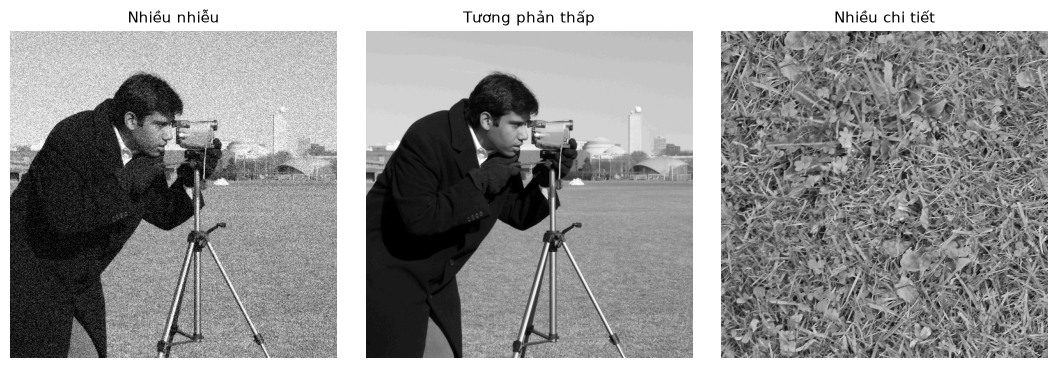

In [9]:
rng = np.random.default_rng(0)
noisy = np.clip(img + rng.normal(0, 25, img.shape), 0, 255).astype(np.uint8)
low_contrast = (100 + img.astype(np.float64) / 255 * 40).astype(np.uint8)
detailed = data.grass()

test_images = {"Nhiều nhiễu": noisy, "Tương phản thấp": low_contrast, "Nhiều chi tiết": detailed}
for name, image in test_images.items():
    print(f"{name:16s} min/max = {image.min()}/{image.max()}")
show_images(list(test_images.values()), list(test_images.keys()), cols=3, save_dir="bai3_anh_dau_vao")

### 3.2. Chạy Canny: mặc định và đã chỉnh tham số
Mỗi ảnh chạy 4 lần: scikit-image mặc định, OpenCV 100/200, và mỗi thư viện một bộ tham số chỉnh theo đặc điểm ảnh:
- **Nhiều nhiễu:** tăng sigma (bước 1) để làm mờ bớt nhiễu trước khi tính gradient.
- **Tương phản thấp:** gradient rất nhỏ nên phải **hạ ngưỡng**. scikit-image có thêm tuỳ chọn `use_quantiles=True`: ngưỡng tính theo phân vị gradient của chính ảnh (0.8 / 0.9 = giữ khoảng 10–20% điểm có gradient lớn nhất) nên không phụ thuộc độ tương phản.
- **Nhiều chi tiết:** tăng sigma và ngưỡng để chỉ giữ cấu trúc lớn, bỏ bớt texture vụn.

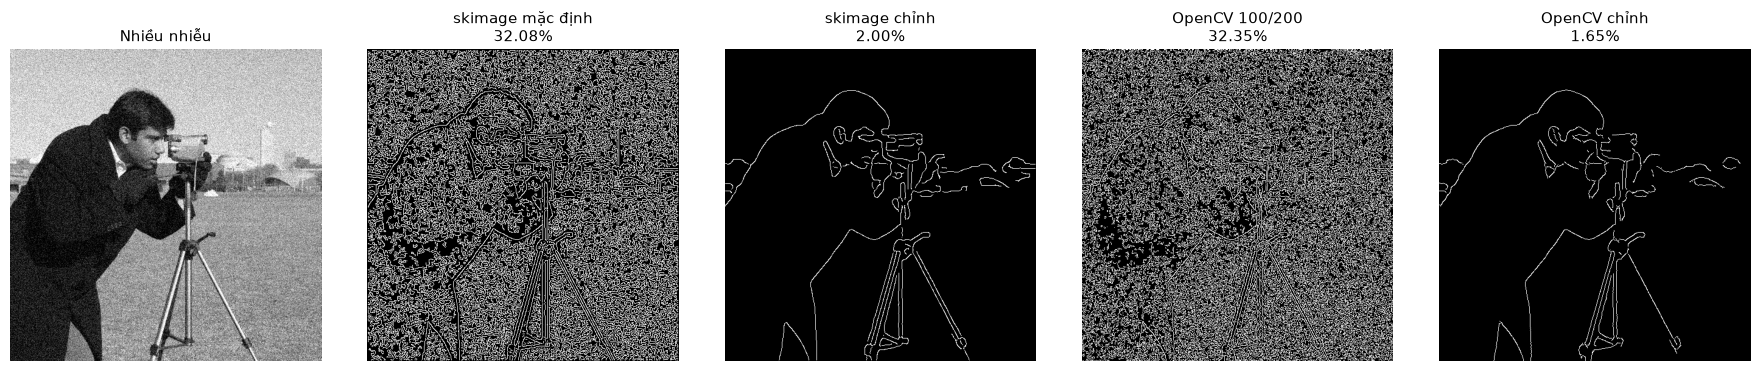

Nhiều nhiễu → tham số chỉnh: sigma=3


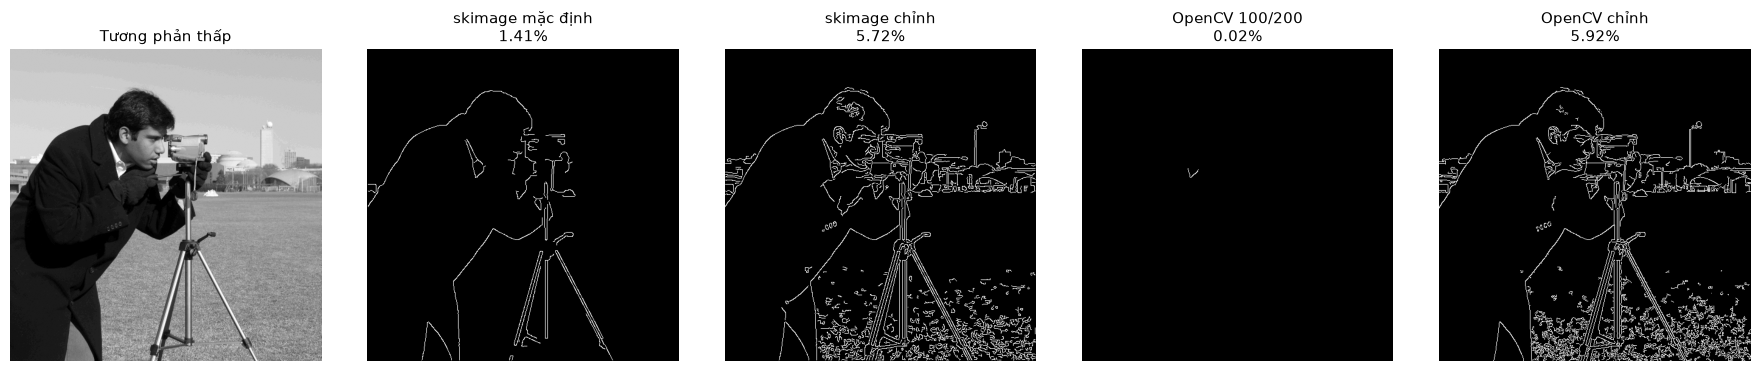

Tương phản thấp → tham số chỉnh: quantile 0.8/0.9 | OpenCV 15/40


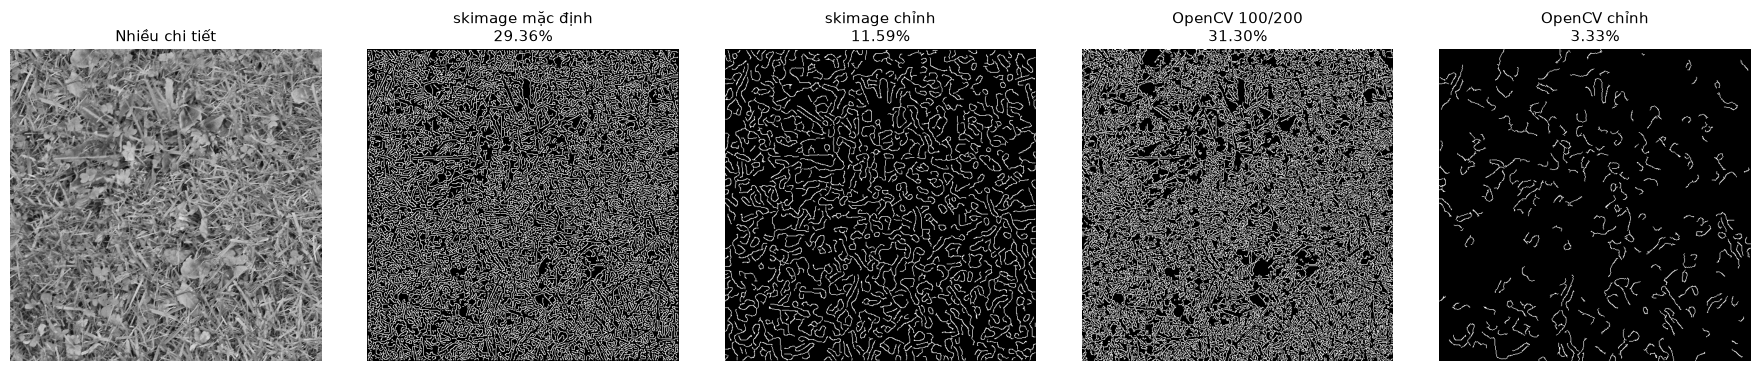

Nhiều chi tiết → tham số chỉnh: sigma=3, ngưỡng cao hơn


In [10]:
settings = {
    "Nhiều nhiễu": dict(sk=dict(sigma=3), cv_sigma=3, cv_thr=(30, 90),
                       label="sigma=3"),
    "Tương phản thấp": dict(sk=dict(sigma=1, low_threshold=0.8, high_threshold=0.9, use_quantiles=True),
                           cv_sigma=0, cv_thr=(15, 40), label="quantile 0.8/0.9 | OpenCV 15/40"),
    "Nhiều chi tiết": dict(sk=dict(sigma=3, low_threshold=20, high_threshold=40), cv_sigma=3, cv_thr=(30, 90),
                          label="sigma=3, ngưỡng cao hơn"),
}

summary = []
for name, image in test_images.items():
    s = settings[name]
    blurred = cv2.GaussianBlur(image, (0, 0), s["cv_sigma"]) if s["cv_sigma"] else image
    results = [feature.canny(image), feature.canny(image, **s["sk"]),
               cv2.Canny(image, 100, 200), cv2.Canny(blurred, *s["cv_thr"])]
    titles = ["skimage mặc định", "skimage chỉnh", "OpenCV 100/200", "OpenCV chỉnh"]
    summary.append((name, [edge_ratio(e) for e in results]))
    folder_name = {"Nhiều nhiễu": "nhieu", "Tương phản thấp": "tuong_phan_thap", "Nhiều chi tiết": "chi_tiet"}[name]
    show_images([image] + results,
                [name] + [f"{t}\n{edge_ratio(e):.2f}%" for t, e in zip(titles, results)],
                cols=5, save_dir=f"bai3_{folder_name}")
    print(name, "→ tham số chỉnh:", s["label"])

### 3.3. Bảng tổng hợp tỉ lệ pixel cạnh (%)

In [11]:
print(f"{'Ảnh':16s} {'sk mặc định':>12s} {'sk chỉnh':>10s} {'cv 100/200':>11s} {'cv chỉnh':>10s}")
for name, ratios in summary:
    print(f"{name:16s} " + " ".join(f"{r:>10.2f}" for r in ratios))
print(f"{'Ảnh gốc camera':16s} {edge_ratio(feature.canny(img)):>10.2f} {'':>10s} {edge_ratio(cv2.Canny(img, 100, 200)):>10.2f}")

Ảnh               sk mặc định   sk chỉnh  cv 100/200   cv chỉnh
Nhiều nhiễu           32.08       2.00      32.35       1.65
Tương phản thấp        1.41       5.72       0.02       5.92
Nhiều chi tiết        29.36      11.59      31.30       3.33
Ảnh gốc camera         9.89                  7.51


### Đánh giá và kết luận bài 3
| Loại ảnh | Tham số mặc định | Sau khi chỉnh | Tham số quan trọng nhất |
|---|---|---|---|
| Nhiều nhiễu | ~32% pixel là cạnh, nhiễu biến thành cạnh giả phủ kín ảnh, không nhìn ra vật | sigma = 3 → còn 2.00% (skimage) / 1.65% (OpenCV), lấy lại được đường viền người và chân máy | **sigma** (bước giảm nhiễu) |
| Tương phản thấp | Gradient rất nhỏ nên hầu như mất hết cạnh: skimage 1.41%, OpenCV 100/200 chỉ 0.02% | Hạ ngưỡng (OpenCV 15/40) hoặc ngưỡng theo phân vị (skimage `use_quantiles`) → ~5.7–5.9%, gần giống kết quả trên ảnh gốc | **ngưỡng thấp/cao** |
| Nhiều chi tiết (cỏ) | ~29–31% cạnh, mỗi ngọn cỏ một cạnh | Tăng sigma + ngưỡng → 11.59% / 3.33%, chỉ giữ các ngọn cỏ, lá lớn | **sigma + ngưỡng** |

**Kết luận:**
- Canny nhạy với nhiễu vì bước 2 dùng đạo hàm (Sobel) — nhiễu là biến thiên mạnh. Bước làm mờ Gaussian là bắt buộc; ảnh càng nhiễu càng cần sigma lớn, đổi lại mất bớt chi tiết nhỏ.
- Ngưỡng cố định phụ thuộc độ tương phản: cùng một ảnh, giảm tương phản thì 100/200 gần như không ra cạnh. Ngưỡng theo phân vị (hoặc tự chỉnh theo ảnh) khắc phục được vấn đề này.
- Với ảnh nhiều texture, Canny không phân biệt "cạnh vật thể" và "cạnh texture"; chỉ giảm được số cạnh bằng sigma/ngưỡng chứ không lấy ra được cấu trúc có ý nghĩa — đó là giới hạn của bộ phát hiện cạnh cục bộ.

## Bài 4. Kết hợp Canny với các kỹ thuật khác
### 4.1. Canny + phân đoạn: tìm các vùng trong ảnh
Ảnh `coins` (các đồng xu trên nền). Quy trình:
1. **Canny** tìm biên các đồng xu. Chọn `sigma=1.5`: thử sigma = 2 thì biên một đồng xu tối (hàng 3, cột 1) bị đứt khoảng 3 px, closing không nối được nên mất đồng xu đó; sigma = 1.5 giữ được biên liền.
2. **Phép đóng (closing)** — xử lý hình thái học ở slide 21–24: biên Canny thường bị đứt vài pixel; closing (giãn nở rồi xói mòn) nối các chỗ đứt để biên thành đường khép kín. Phần tử cấu trúc **hình tròn** (`MORPH_ELLIPSE`) vì đồng xu tròn.
3. **Tô kín vùng (ngoài slide):** `cv2.findContours` lấy đường bao ngoài của mỗi biên khép kín, `cv2.drawContours(..., thickness=-1)` tô đặc bên trong → mỗi đường bao thành một **vùng**. Đây là bước biến "đường biên" của Canny thành "vùng" — yêu cầu của đề.
4. **Lọc theo diện tích (ngoài slide):** bỏ vùng nhỏ hơn `MIN_AREA` pixel — đó là các mẩu cạnh vụn chưa khép kín, không phải đồng xu.

Số đường bao tìm được: 25 → giữ lại 24 vùng có diện tích ≥ 300 px


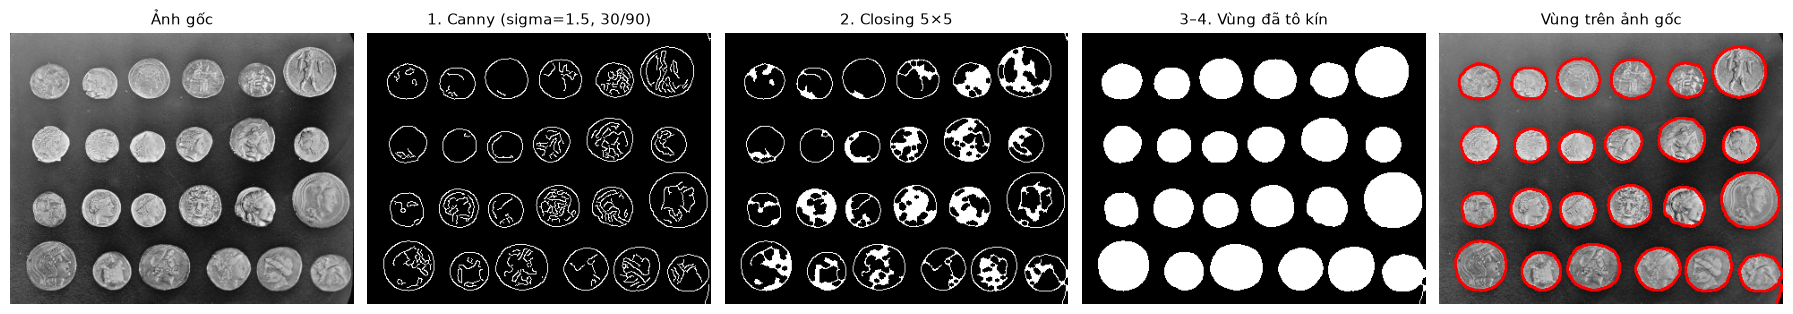

In [12]:
coins = data.coins()
coin_edges = cv2.Canny(cv2.GaussianBlur(coins, (0, 0), 1.5), 30, 90)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
closed = cv2.morphologyEx(coin_edges, cv2.MORPH_CLOSE, kernel)

MIN_AREA = 300
contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
regions = [c for c in contours if cv2.contourArea(c) >= MIN_AREA]

mask = np.zeros_like(coins)
cv2.drawContours(mask, regions, -1, 255, thickness=-1)
overlay = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB)
cv2.drawContours(overlay, regions, -1, (255, 0, 0), 2)

print(f"Số đường bao tìm được: {len(contours)} → giữ lại {len(regions)} vùng có diện tích ≥ {MIN_AREA} px")
show_images([coins, coin_edges, closed, mask, overlay],
            ["Ảnh gốc", "1. Canny (sigma=1.5, 30/90)", "2. Closing 5×5", "3–4. Vùng đã tô kín", "Vùng trên ảnh gốc"],
            cols=5, save_dir="bai4_phan_doan")

**Nhận xét 4.1:** Canny + closing + tô kín tìm được **24/24 đồng xu**, mỗi đồng xu thành một vùng riêng. Bước closing là quan trọng: biên Canny có nhiều chỗ đứt nhỏ, không nối thì không tô được vùng. Kernel không được quá lớn: thử 9×9 hoặc 11×11 thì các đồng xu gần nhau bị nối dính thành một vùng (chỉ còn 20–22 vùng). Hạn chế: phương pháp chỉ hoạt động khi biên đối tượng **khép kín** và vật tách khỏi nền — đúng như ảnh đồng xu.

### 4.2. Canny + nhận dạng hình dạng: tìm các đối tượng
**Ảnh test (ngoài slide):** vẽ sẵn tam giác, hình vuông, chữ nhật, ngũ giác, hình tròn rồi cộng nhiễu nhẹ — dùng để **biết trước đáp án** và kiểm tra nhận dạng đúng hay sai.

Quy trình:
1. **Canny** tìm biên các hình.
2. **Closing** nối chỗ biên đứt (như 4.1).
3. **Nhận dạng hình dạng (ngoài slide):** `cv2.findContours` lấy đường bao từng đối tượng; `cv2.approxPolyDP` xấp xỉ đường bao bằng đa giác ít đỉnh nhất, sai lệch tối đa 4% chu vi. Đếm số đỉnh: 3 → tam giác, 4 → tứ giác (tỉ lệ cạnh ≈ 1 là vuông, ngược lại là chữ nhật), 5 → ngũ giác, nhiều đỉnh → hình tròn.

Đối tượng tìm được (trái → phải): ['Tam giac', 'Vuong', 'Tron', 'Chu nhat', 'Tron', 'Ngu giac']


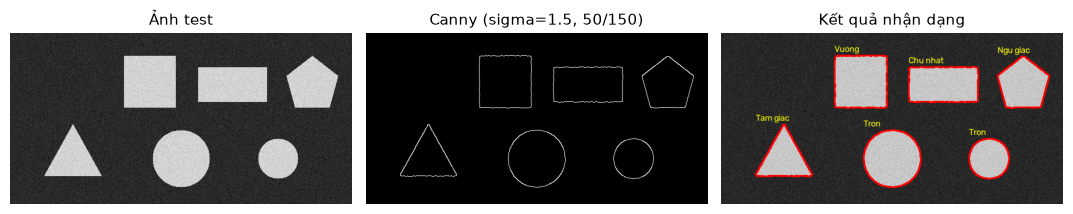

In [13]:
rng = np.random.default_rng(0)
shapes = np.full((300, 600), 40, np.uint8)
cv2.fillPoly(shapes, [np.array([[60, 250], [160, 250], [110, 160]])], 200)            # tam giác
cv2.rectangle(shapes, (200, 40), (290, 130), 200, -1)                                  # vuông
cv2.rectangle(shapes, (330, 60), (450, 120), 200, -1)                                  # chữ nhật
cv2.fillPoly(shapes, [np.array([[530, 40], [575, 75], [560, 130], [500, 130], [485, 75]])], 200)  # ngũ giác
cv2.circle(shapes, (300, 220), 50, 200, -1)                                            # tròn
cv2.circle(shapes, (470, 220), 35, 200, -1)                                            # tròn
shapes = np.clip(shapes + rng.normal(0, 10, shapes.shape), 0, 255).astype(np.uint8)
cv2.imwrite("du_lieu/hinh_dang.png", shapes)

def shape_name(contour):
    """Đặt tên hình theo số đỉnh của đa giác xấp xỉ."""
    approx = cv2.approxPolyDP(contour, 0.04 * cv2.arcLength(contour, True), True)
    if len(approx) == 3:
        return "Tam giac"
    if len(approx) == 4:
        _, _, w, h = cv2.boundingRect(approx)
        return "Vuong" if 0.9 <= w / h <= 1.1 else "Chu nhat"
    if len(approx) == 5:
        return "Ngu giac"
    return "Tron"

shape_edges = cv2.Canny(cv2.GaussianBlur(shapes, (0, 0), 1.5), 50, 150)
shape_closed = cv2.morphologyEx(shape_edges, cv2.MORPH_CLOSE, kernel)
contours, _ = cv2.findContours(shape_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

labeled = cv2.cvtColor(shapes, cv2.COLOR_GRAY2RGB)
found = []
for c in contours:
    if cv2.contourArea(c) < MIN_AREA:
        continue
    name = shape_name(c)
    x, y, w, h = cv2.boundingRect(c)
    found.append((x, name))
    cv2.drawContours(labeled, [c], -1, (255, 0, 0), 2)
    cv2.putText(labeled, name, (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1, cv2.LINE_AA)

print("Đối tượng tìm được (trái → phải):", [n for _, n in sorted(found)])
show_images([shapes, shape_edges, labeled], ["Ảnh test", "Canny (sigma=1.5, 50/150)", "Kết quả nhận dạng"],
            cols=3, save_dir="bai4_nhan_dang_hinh")

**Áp dụng nhận dạng cho ảnh thật:** dùng lại các vùng đồng xu ở 4.1 — nếu Canny + closing cho đường bao tốt thì mỗi đồng xu phải được nhận là "Tron".

In [14]:
coin_names = [shape_name(c) for c in regions]
print("Kết quả nhận dạng các vùng đồng xu:", {n: coin_names.count(n) for n in set(coin_names)})

Kết quả nhận dạng các vùng đồng xu: {'Ngu giac': 1, 'Tron': 23}


**Nhận xét 4.2:**
- Ảnh test: nhận dạng đúng **6/6 hình** (tam giác, vuông, tròn, chữ nhật, tròn, ngũ giác). Lúc đầu đặt chữ nhật và ngũ giác cách nhau 5 px thì closing 5×5 nối biên hai hình làm một → nhận sai; phải để các vật cách nhau xa hơn kích thước kernel.
- Ảnh đồng xu: 23/24 vùng nhận là "Tron", 1 vùng bị nhận là "Ngu giac" vì đường bao đồng xu đó hơi méo nên đa giác xấp xỉ chỉ còn 5 đỉnh. Cách nhận dạng theo số đỉnh đơn giản, dễ giải thích, nhưng phụ thuộc vào chất lượng biên Canny và tham số sai số 4% chu vi.